## 1. [Deprecated Sentiment Analysis]

In [ ]:
# Paths are relative to the notebooks/ folder of this repository.
# On Google Colab, clone the repository first and run from notebooks/:
#   !git clone https://github.com/Syukrondzeko/natural-disaster-app-review-analysis.git
#   %cd natural-disaster-app-review-analysis/notebooks
DATA_DIR = "../data"

In [5]:
# import pandas as pd

# file_path = f"{DATA_DIR}/4_topics/all_clusters_with_final_cluster.xlsx"
# df = pd.read_excel(file_path)


In [7]:
# !pip install -q vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.6 MB/s eta 0:00:00


In [11]:
# from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
# import time
# import pandas as pd

# analyzer = SentimentIntensityAnalyzer()

# compound_scores = []
# sentiment_labels = []
# sentiment_scaled = []

# start_time = time.time()

# for i, sentence in enumerate(df['content'], 1):
#     vs = analyzer.polarity_scores(sentence)
#     compound = vs['compound']  # range [-1, 1]

#     # --------------------------------
#     # Sentiment label
#     # --------------------------------
#     if compound >= 0.05:
#         sentiment = "positive"
#     elif compound <= -0.05:
#         sentiment = "negative"
#     else:
#         sentiment = "neutral"

#     # --------------------------------
#     # Scale compound score to 1–5
#     # Linear mapping: [-1,1] → [1,5]
#     # --------------------------------
#     sentiment_1_to_5 = 1 + (compound + 1) * 2
#     sentiment_1_to_5 = round(sentiment_1_to_5, 2)

#     compound_scores.append(compound)
#     sentiment_labels.append(sentiment)
#     sentiment_scaled.append(sentiment_1_to_5)

#     # Progress print
#     if i % 1000 == 0:
#         elapsed_time = time.time() - start_time
#         print(f"Processed {i} sentences in {elapsed_time:.2f} seconds.")

# total_time = time.time() - start_time
# print(f"Total time taken: {total_time:.2f} seconds.")

# # --------------------------------
# # Add columns to DataFrame
# # --------------------------------
# df['coumpund_score'] = compound_scores
# df['sentiment'] = sentiment_labels
# df['sentiment_score'] = sentiment_scaled


Processed 1000 sentences in 0.33 seconds.
Processed 2000 sentences in 0.74 seconds.
Processed 3000 sentences in 0.84 seconds.
Processed 4000 sentences in 0.94 seconds.
Processed 5000 sentences in 1.08 seconds.
Processed 6000 sentences in 1.17 seconds.
Processed 7000 sentences in 1.24 seconds.
Total time taken: 1.36 seconds.


In [13]:
# import os

# output_path = f"{DATA_DIR}/5_sentiment/all_clusters_with_sentiment.xlsx"

# df.to_excel(output_path, index=False)

# print("Saved file to:")
# print(output_path)
# print("File exists:", os.path.exists(output_path))


Saved file to:
/content/drive/MyDrive/Natural Disaster/Dataset/refining/all_clusters_with_sentiment.xlsx
File exists: True


## Sorting Cluster Based on Alphabetical

- Cluster 1: Access Permission
- Cluster 2: Alert Functionality
- Cluster 3: Alert Sounds
- Cluster 4: App Configuration
- Cluster 5: App Crashes
- Cluster 6: App Updates
- Cluster 7: Battery Consumption
- Cluster 8: Device Compatibility
- Cluster 9: Geographical Coverage
- Cluster 10: Keep Updates
- Cluster 11: Laggy
- Cluster 12: Language
- Cluster 13: Location Functionality
- Cluster 14: Map Features
- Cluster 15: Pricing Scheme
- Cluster 16: Reliability
- Cluster 17: Server Connection
- Cluster 18: Setting Option
- Cluster 19: Shelter
- Cluster 20: Sign In and Log In
- Cluster 21: Travelling
- Cluster 22: User Experience
- Cluster 23: User Experience
- Cluster 24: User Interface
- Cluster 25: Watch Zone


In [28]:
import pandas as pd

# Read Excel
file_path = f"{DATA_DIR}/5_sentiment/all_clusters_with_sentiment.xlsx"
df = pd.read_excel(file_path)

# Optional: rename app value
df["app"] = df["app"].replace("geonet quake", "geonet")

# Original old cluster mapping
old_cluster_to_name = {
    1: "Watch Zone",
    2: "Alert Functionality",
    3: "Reliability",
    4: "Geographical Coverage",
    5: "App Updates",
    6: "Keep Updates",
    7: "Pricing Scheme",
    8: "Location Functionality",
    9: "Alert Sounds",
    10: "Battery Consumption",
    11: "App Crashes",
    12: "Map Features",
    13: "User Experience",
    14: "Device Compatibility",
    15: "Setting Option",
    16: "Server Connection",
    17: "Shelter",
    18: "User Interface",
    19: "Laggy",
    20: "Access Permission",
    21: "User Experience",
    22: "Travelling",
    23: "Language",
    24: "Sign In and Log In",
    25: "App Configuration"
}

# --- Step 1: Merge clusters as requested ---
# Merge the two User Experience clusters into one
old_cluster_to_name[21] = "User Experience"

# Merge Cluster 15: Setting Option and Cluster 25: App Configuration → "Setting Option"
old_cluster_to_name[25] = "Setting Option"

# Merge Cluster 22: Travelling and Cluster 23: Language → "Language"
old_cluster_to_name[22] = "Language"

# --- Step 2: Alphabetically sort unique cluster names ---
sorted_names = sorted(set(old_cluster_to_name.values()))

# --- Step 3: Map old cluster number to new alphabetical number and name ---
old_to_sorted_number = {}
old_to_sorted_name = {}
for new_num, name in enumerate(sorted_names, start=1):
    # Find all old cluster numbers matching this name
    old_keys = [k for k, v in old_cluster_to_name.items() if v == name]
    for k in old_keys:
        old_to_sorted_number[k] = new_num
        old_to_sorted_name[k] = name

# Apply mapping to dataframe
df["final_sorted_cluster"] = df["final_cluster"].map(old_to_sorted_number)
df["final_sorted_cluster_name"] = df["final_cluster"].map(old_to_sorted_name)

# Optional: check result
print(df[["final_cluster", "final_sorted_cluster", "final_sorted_cluster_name"]].head())
print("Unique final_sorted_cluster numbers:", df["final_sorted_cluster"].nunique())
print("Unique final_sorted_cluster names:", df["final_sorted_cluster_name"].nunique())

# --- Step 4: Save to Excel ---
output_path = f"{DATA_DIR}/5_sentiment/all_clusters_with_sentiment_sorted.xlsx"
df.to_excel(output_path, index=False)
print(f"Saved sorted data to: {output_path}")


   final_cluster  final_sorted_cluster final_sorted_cluster_name
0              1                    22                Watch Zone
1              1                    22                Watch Zone
2              1                    22                Watch Zone
3              1                    22                Watch Zone
4              1                    22                Watch Zone
Unique final_sorted_cluster numbers: 22
Unique final_sorted_cluster names: 22
Saved sorted data to: /content/drive/MyDrive/Natural Disaster/Dataset/refining/all_clusters_with_sentiment_sorted.xlsx


In [29]:
# Get unique sorted cluster numbers
unique_clusters = sorted(df["final_sorted_cluster"].unique())

# Loop and print
for num in unique_clusters:
    # Get the cluster name corresponding to this number
    name = df.loc[df["final_sorted_cluster"] == num, "final_sorted_cluster_name"].iloc[0]
    print(f"Cluster {num}: {name}")


Cluster 1: Access Permission
Cluster 2: Alert Functionality
Cluster 3: Alert Sounds
Cluster 4: App Crashes
Cluster 5: App Updates
Cluster 6: Battery Consumption
Cluster 7: Device Compatibility
Cluster 8: Geographical Coverage
Cluster 9: Keep Updates
Cluster 10: Laggy
Cluster 11: Language
Cluster 12: Location Functionality
Cluster 13: Map Features
Cluster 14: Pricing Scheme
Cluster 15: Reliability
Cluster 16: Server Connection
Cluster 17: Setting Option
Cluster 18: Shelter
Cluster 19: Sign In and Log In
Cluster 20: User Experience
Cluster 21: User Interface
Cluster 22: Watch Zone


## Regex Language Cluster

In [ ]:
import pandas as pd

# Read Excel
file_path = f"{DATA_DIR}/5_sentiment/all_clusters_with_sentiment_sorted.xlsx"
df = pd.read_excel(file_path)

# temp_df = df[df.final_sorted_cluster == 22]
# for i in range(0,250):
#   try:
#     text = temp_df.iloc[i].content_translated
#     print(text)
#     print("\n")
#   except:
#     pass

# Ensure the column is string
df["content_translated"] = df["content_translated"].astype(str)

# Single-word language-related keywords
language_keywords = [
    "language",
    "english",
    "translate",
    "translated",
    "translation",
    "foreign",
    "multilingual",
    "lingual",
    "dialect",
    "vocabulary",
    "wording",
    "phrasing"
]

# Create regex with word boundaries
language_regex = r"\b(" + "|".join(language_keywords) + r")\b"

# Boolean mask for language-related reviews
language_mask = df["content_translated"].str.contains(
    language_regex,
    case=False,
    na=False,
    regex=True
)

# Assign temporary cluster to these rows
df.loc[language_mask, "final_sorted_cluster"] = 99
df.loc[language_mask, "final_sorted_cluster_name"] = "temporary"

# Optional: see how many were flagged
print("Total language-related reviews flagged:", language_mask.sum())
print()

# Optional: preview flagged rows
print(df.loc[language_mask, ["app", "content_translated", "final_sorted_cluster", "final_sorted_cluster_name"]].head(10))

# Keep only rows where final_sorted_cluster is NOT 11
df = df[df["final_sorted_cluster"] != 11].reset_index(drop=True)

# Optional: check
print("Total rows after removing cluster 11:", len(df))

# Create a mask for rows where final_sorted_cluster == 99
mask_temp = df["final_sorted_cluster"] == 99

# Update these rows
df.loc[mask_temp, "final_sorted_cluster"] = 11
df.loc[mask_temp, "final_sorted_cluster_name"] = "Language"

# Optional: check
print("Rows updated to cluster 11 (Language):", mask_temp.sum())
print(df.loc[mask_temp, ["content_translated", "final_sorted_cluster", "final_sorted_cluster_name"]].head(10))

# # Save DataFrame to Excel
df.to_excel(f"{DATA_DIR}/5_sentiment/final_data_penultimate.xlsx", index=False)

# print("Data saved as final_data_penultimate.xlsx")

import pandas as pd

# Assuming df is already loaded and updated

# 1️⃣ Drop unnecessary columns
cols_to_drop = [
    "source_file",
    "final_cluster",
    "subcluster_topic",
    "refined_topic",
    "topic_probability",
    "cluster",
    "content"
]
df = df.drop(columns=cols_to_drop)

# 2️⃣ Rename columns
df = df.rename(columns={
    "id": "review_id",
    "final_sorted_cluster": "cluster_id",
    "final_sorted_cluster_name": "cluster_name",
    "content_translated": "review",
    "score": "user_rating"
})

# 3️⃣ Reorder columns
new_order = [
    "review_id",
    "review",
    "cluster_id",
    "cluster_name",
    "user_rating",
    "sentiment_score",
    "sentiment",
    "coumpund_score"
]
df = df[new_order]

# 4️⃣ Optional: preview
print(df.head())

# 5️⃣ Save to Excel
df.to_excel(f"{DATA_DIR}/5_sentiment/final_data.xlsx", index=False)

print("Data saved as final_data.xlsx")


In [ ]:
# # Count occurrences of each cluster name
# cluster_counts = df["cluster_name"].value_counts()

# # Optional: convert to DataFrame for nicer display
# cluster_counts_df = cluster_counts.reset_index()
# cluster_counts_df.columns = ["Cluster Name", "Count"]

# # Print sorted by most frequent
# print(cluster_counts_df)

# # If you want in the same format with cluster numbers:
# cluster_number_mapping = df.drop_duplicates(subset=["cluster_name"])[
#     ["cluster_name", "cluster_id"]
# ].set_index("cluster_name")["cluster_id"].to_dict()




## Stat Calc

In [12]:
import pandas as pd
import numpy as np

# Raw data
downloads = [
    "100+","14K+","7K+","600+","700+","3K+","45K+","22K+","2K+","11K+","2K+","2K+",
    "20+","4K+","900+","200+","60+","11K+","1K+","2K+","800+","5K+","1K+","200+","900+",
    "3K+","10K+","90+","13K+","10+","84K+","111K+","81K+","81K+","600+","74K+","600+"
]

ratings = [
    3.3,4.7,4.7,3.5,4.2,4.8,4.7,4.7,4.6,4.6,4.7,4.6,
    3,4.9,3.7,2.3,4.6,4.7,3.2,4.8,4.7,4.8,3.3,2.6,2.2,
    4.7,4.7,2.7,4.7,1.5,4.3,4.8,4.6,4.6,2.9,4.8,4.3
]

# Function to convert Downloads to numeric
def parse_download(d):
    d = d.replace('+','').upper().strip()
    if 'K' in d:
        return float(d.replace('K','')) * 1_000
    elif 'M' in d:
        return float(d.replace('M','')) * 1_000_000
    else:
        return float(d)

downloads_num = [parse_download(d) for d in downloads]

# Create dataframe
df = pd.DataFrame({
    'Downloads': downloads_num,
    'Rating': ratings
})

# Compute statistics
stats = pd.DataFrame({
    'Downloads': [df['Downloads'].mean(), df['Downloads'].median(), df['Downloads'].max(), df['Downloads'].min()],
    'Rating': [df['Rating'].mean(), df['Rating'].median(), df['Rating'].max(), df['Rating'].min()]
}, index=['Mean','Median','Max', 'Min'])

print(stats)


            Downloads    Rating
Mean     16075.135135  4.067568
Median    2000.000000  4.600000
Max     111000.000000  4.900000
Min         10.000000  1.500000


In [13]:
import pandas as pd
import numpy as np

# Raw data
downloads = [
    "50K+","100K+","100K+","10K+","500K+","10K+","10K+","1M+","100K+","100K+","1M+","50K+",
    "500K+","10M+","100K+","500K+","100K+","100K+","500K+","5K+","10K+","10K+","100K+","100K+",
    "1M+","100K+","100K+","50K+","100K+","1M+","1M+","100K+","10K+","1M+","10M+","50K+","500K+",
    "10K+","100K+","1M+","100K+","50K+","1M+","5M+","100K+","10K+","100K+","50K+","50K+","10K+",
    "10K+","10K+","100K+","10K+","1M+","1M+","1M+","1M+"
]

ratings = [
    "3.3","4.7","4.5","3.4","3,4","4.7","4.5","3.6","4.1","4.2","4.6","4.4",
    "4.3","4.3","4.6","3","4.5","4.3","4.5","4.5","4.2","3.3","4.5","3","4.4","2.7",
    "4.2","2,1","4.1","4.4","2.5","3.7","4.3","4.6","4.6","4.7","4.7","4.7","3.5","3.8",
    "3.3","3.4","4.3","2.6","4","3","2.6","4.7","3.6","4.1","2.8","2.8","4.9","3.1","2.6",
    "4.3","4.4","4.7"
]

# Clean ratings: replace comma with dot and convert to float
ratings = [float(r.replace(',', '.')) for r in ratings]

# Function to convert Downloads to numeric
def parse_download(d):
    d = d.replace('+','').upper().strip()
    if 'K' in d:
        return float(d.replace('K','')) * 1_000
    elif 'M' in d:
        return float(d.replace('M','')) * 1_000_000
    else:
        return float(d)

downloads_num = [parse_download(d) for d in downloads]

# Create dataframe
df = pd.DataFrame({
    'Downloads': downloads_num,
    'Rating': ratings
})

# Compute statistics
stats = pd.DataFrame({
    'Downloads': [
        df['Downloads'].min(),
        df['Downloads'].mean(),
        df['Downloads'].median(),
        df['Downloads'].max()
    ],
    'Rating': [
        df['Rating'].min(),
        df['Rating'].mean(),
        df['Rating'].median(),
        df['Rating'].max()
    ]
}, index=['Min','Mean','Median','Max'])

print(stats)


           Downloads    Rating
Min     5.000000e+03  2.100000
Mean    7.202586e+05  3.906897
Median  1.000000e+05  4.200000
Max     1.000000e+07  4.900000


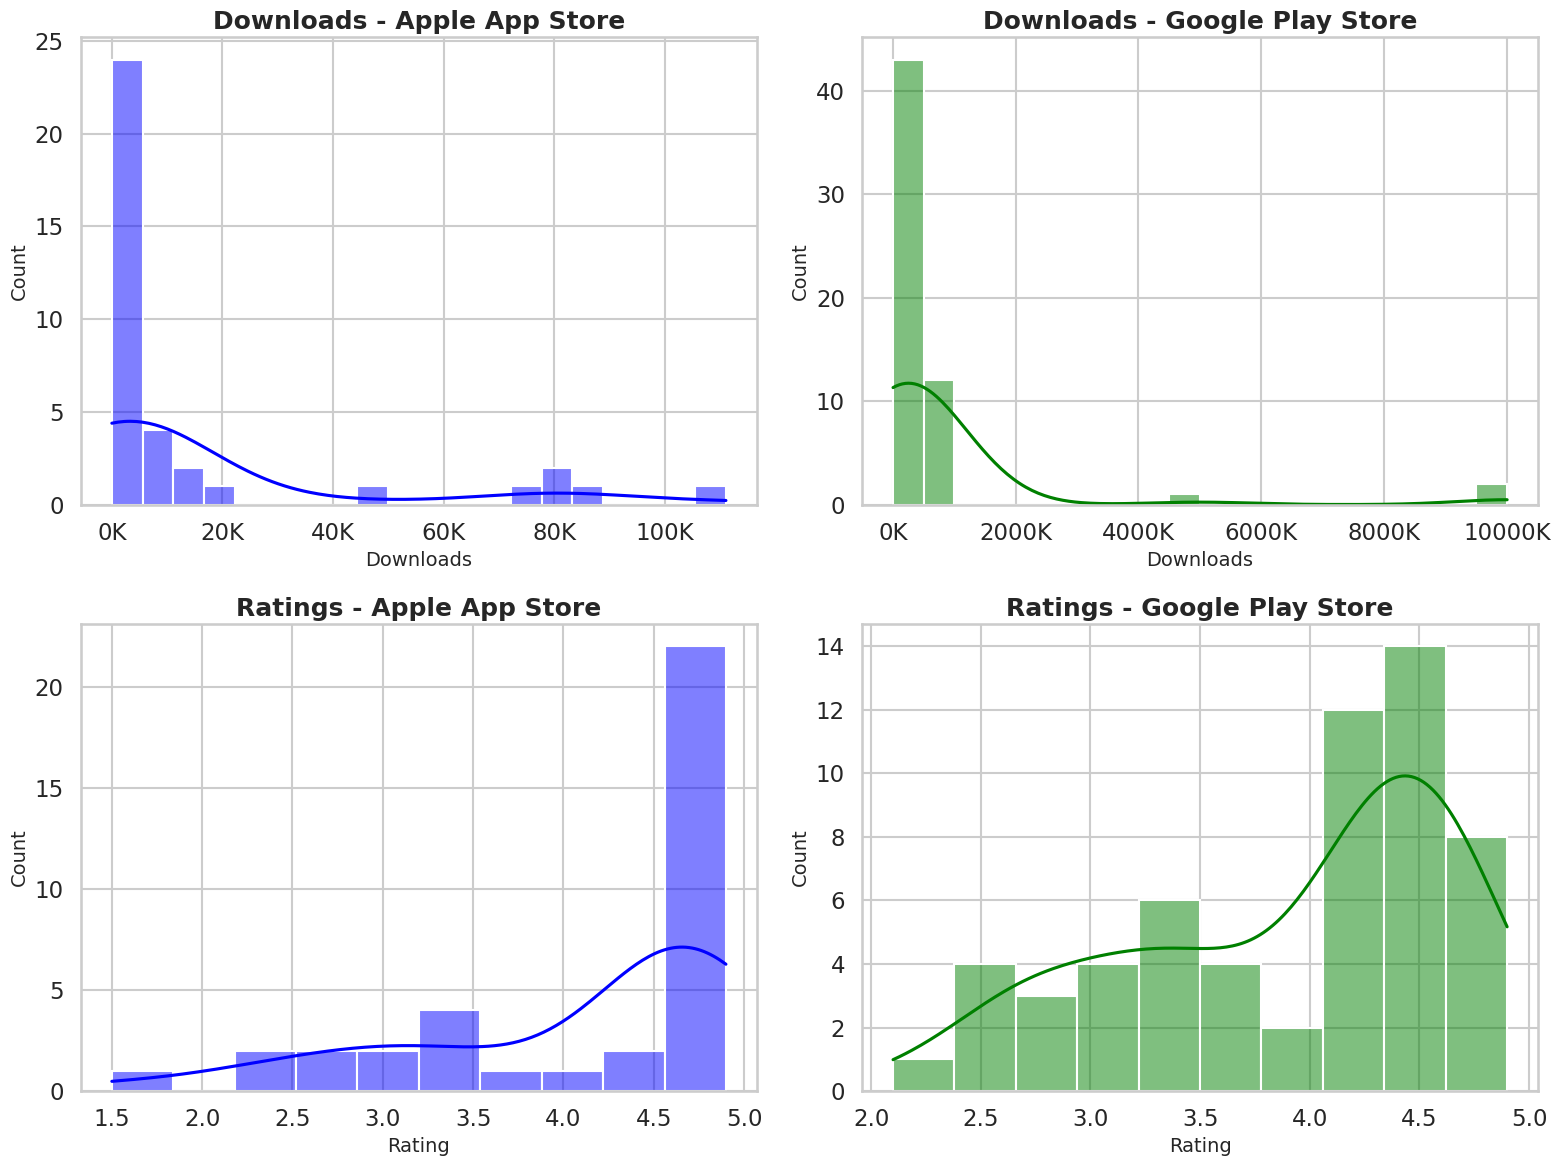

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

# --- Sample cleaned data ---
downloads_appstore = [
    100, 14000, 7000, 600, 700, 3000, 45000, 22000, 2000, 11000, 2000, 2000,
    20, 4000, 900, 200, 60, 11000, 1000, 2000, 800, 5000, 1000, 200, 900, 3000,
    10000, 90, 13000, 10, 84000, 111000, 81000, 81000, 600, 74000, 600
]

ratings_appstore = [
    3.3,4.7,4.7,3.5,4.2,4.8,4.7,4.7,4.6,4.6,4.7,4.6,
    3,4.9,3.7,2.3,4.6,4.7,3.2,4.8,4.7,4.8,3.3,2.6,2.2,
    4.7,4.7,2.7,4.7,1.5,4.3,4.8,4.6,4.6,2.9,4.8,4.3
]

downloads_playstore = [
    50000,100000,100000,10000,500000,10000,10000,1000000,100000,100000,
    1000000,50000,500000,10000000,100000,500000,100000,100000,500000,5000,
    10000,10000,100000,100000,1000000,100000,100000,50000,100000,1000000,
    1000000,100000,10000,1000000,10000000,50000,500000,10000,100000,1000000,
    100000,50000,1000000,5000000,100000,10000,100000,50000,50000,10000,10000,
    10000,100000,10000,1000000,1000000,1000000,1000000
]

ratings_playstore = [
    3.3,4.7,4.5,3.4,3.4,4.7,4.5,3.6,4.1,4.2,4.6,4.4,
    4.3,4.3,4.6,3,4.5,4.3,4.5,4.5,4.2,3.3,4.5,3,4.4,2.7,
    4.2,2.1,4.1,4.4,2.5,3.7,4.3,4.6,4.6,4.7,4.7,4.7,3.5,3.8,
    3.3,3.4,4.3,2.6,4,3,2.6,4.7,3.6,4.1,2.8,2.8,4.9,3.1,2.6,
    4.3,4.4,4.7
]

# --- Seaborn style for professional journal ---
sns.set_style("whitegrid")
sns.set_context("talk")  # suitable for journals

# --- Create figure ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))  # 2x2 grid

# --- Top row: Downloads distributions ---
sns.histplot(downloads_appstore, bins=20, kde=True, color='blue', ax=axes[0,0])
axes[0,0].set_title("Downloads - Apple App Store", fontname='Times New Roman', fontsize=18, fontweight='bold')
axes[0,0].set_xlabel("Downloads", fontname='Times New Roman', fontsize=14)
axes[0,0].set_ylabel("Count", fontname='Times New Roman', fontsize=14)
axes[0,0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x/1000)}K'))

sns.histplot(downloads_playstore, bins=20, kde=True, color='green', ax=axes[0,1])
axes[0,1].set_title("Downloads - Google Play Store", fontname='Times New Roman', fontsize=18, fontweight='bold')
axes[0,1].set_xlabel("Downloads", fontname='Times New Roman', fontsize=14)
axes[0,1].set_ylabel("Count", fontname='Times New Roman', fontsize=14)
axes[0,1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x/1000)}K'))

# --- Bottom row: Ratings distributions ---
sns.histplot(ratings_appstore, bins=10, kde=True, color='blue', ax=axes[1,0])
axes[1,0].set_title("Ratings - Apple App Store", fontname='Times New Roman', fontsize=18, fontweight='bold')
axes[1,0].set_xlabel("Rating", fontname='Times New Roman', fontsize=14)
axes[1,0].set_ylabel("Count", fontname='Times New Roman', fontsize=14)

sns.histplot(ratings_playstore, bins=10, kde=True, color='green', ax=axes[1,1])
axes[1,1].set_title("Ratings - Google Play Store", fontname='Times New Roman', fontsize=18, fontweight='bold')
axes[1,1].set_xlabel("Rating", fontname='Times New Roman', fontsize=14)
axes[1,1].set_ylabel("Count", fontname='Times New Roman', fontsize=14)

# --- Layout ---
plt.tight_layout()
plt.show()


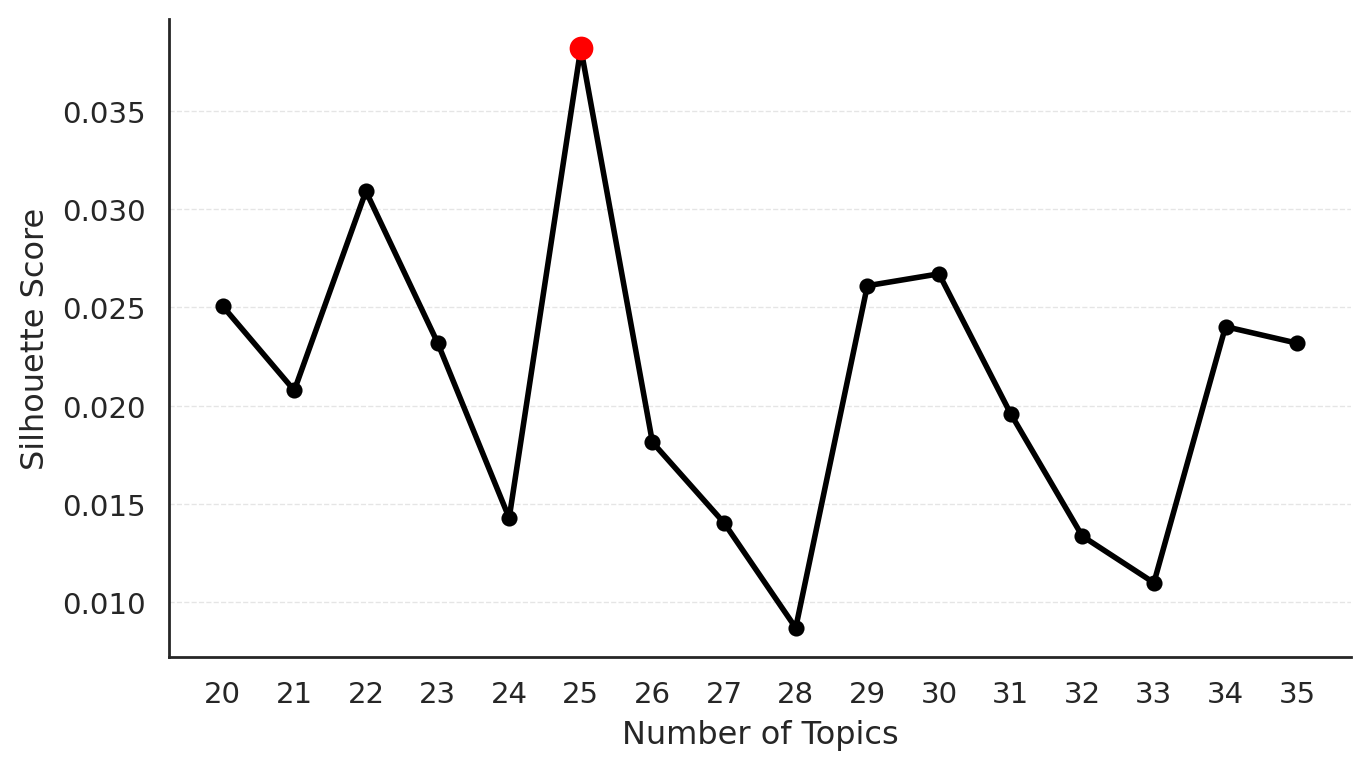

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df_path = f"{DATA_DIR}/4_topics/exp/metrics_summary.xlsx"
df = pd.read_excel(df_path).sort_values("nr_topics")

# --- GLOBAL rendering fixes ---
plt.rcParams["figure.dpi"] = 200
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.family"] = "serif"
plt.rcParams["axes.linewidth"] = 0.8

sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.2
)

fig, ax = plt.subplots(figsize=(7, 4))

# Main silhouette curve (pure black, crisp)
ax.plot(
    df["nr_topics"],
    df["silhouette"],
    color="black",
    linewidth=2
)

# Small markers
ax.scatter(
    df["nr_topics"],
    df["silhouette"],
    color="black",
    s=25,
    zorder=3
)

# Highlight best silhouette
best_idx = df["silhouette"].idxmax()
ax.scatter(
    df.loc[best_idx, "nr_topics"],
    df.loc[best_idx, "silhouette"],
    color="red",
    s=60,
    zorder=4
)

# Labels
ax.set_xlabel("Number of Topics")
ax.set_ylabel("Silhouette Score")

ax.set_xticks(df["nr_topics"])

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Subtle y-grid only
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


## Redo Sentiment Analysis

In [12]:
!pip install -q vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.6 MB/s eta 0:00:00


In [49]:
import pandas as pd

# Read the Excel file
file_path = f"{DATA_DIR}/5_sentiment/final_data.xlsx"
df = pd.read_excel(file_path)

df = df[['review_id', 'review', 'cluster_id', 'cluster_name', 'user_rating']]

In [50]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import time
import pandas as pd

# ----------------------------
# Initialize VADER
# ----------------------------
analyzer = SentimentIntensityAnalyzer()

# ----------------------------
# Adjusted thresholds for neutral
# ----------------------------
neutral_lower = 0.1
neutral_upper = 0.4

compound_scores = []
sentiment_labels = []

start_time = time.time()

# ----------------------------
# Compute sentiment for each review
# ----------------------------
for i, sentence in enumerate(df['review'], 1):
    vs = analyzer.polarity_scores(sentence)
    compound = vs['compound']  # range [-1, 1]

    # Sentiment label with narrower neutral range
    if compound > neutral_upper:
        sentiment = "Positive"
    elif compound < neutral_lower:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    compound_scores.append(compound)
    sentiment_labels.append(sentiment)

    # Optional progress print
    if i % 1000 == 0:
        elapsed_time = time.time() - start_time
        print(f"Processed {i} sentences in {elapsed_time:.2f} seconds.")

total_time = time.time() - start_time
print(f"Total time taken: {total_time:.2f} seconds.")

# ----------------------------
# Add columns to DataFrame
# ----------------------------
df['compound_score'] = compound_scores
df['sentiment'] = sentiment_labels

# ----------------------------
# Value counts of sentiment labels
# ----------------------------
sentiment_counts = df['sentiment'].value_counts().reindex(['Negative','Neutral','Positive'])
print("\nSentiment Distribution:")
print(sentiment_counts)


Processed 1000 sentences in 0.14 seconds.
Processed 2000 sentences in 0.32 seconds.
Processed 3000 sentences in 0.43 seconds.
Processed 4000 sentences in 0.55 seconds.
Processed 5000 sentences in 0.73 seconds.
Processed 6000 sentences in 0.85 seconds.
Processed 7000 sentences in 0.93 seconds.
Total time taken: 1.00 seconds.

Sentiment Distribution:
sentiment
Negative    3425
Neutral      963
Positive    3279
Name: count, dtype: int64


In [52]:
# Define a function to map ratings/scores to categories
def categorize_rating(x):
    if x in [1, 2]:
        return 'Negative'
    elif x == 3:
        return 'Neutral'
    elif x in [4, 5]:
        return 'Positive'

# Apply the mapping to user_rating and rounded sentiment_score
df['user_rating_category'] = df['user_rating'].apply(categorize_rating)

# Count values for the categories
user_rating_cat_counts = df['user_rating_category'].value_counts().reindex(['Negative','Neutral','Positive'])
sentiment_cat_counts = df['sentiment'].value_counts().reindex(['Negative','Neutral','Positive'])

# Calculate percentages
user_rating_cat_percent = (user_rating_cat_counts / len(df) * 100).round(2)
sentiment_cat_percent = (sentiment_cat_counts / len(df) * 100).round(2)

# Display counts and percentages
print("User Rating Categories:")
print(user_rating_cat_counts)
print("\nUser Rating Percentages (%):")
print(user_rating_cat_percent)

print("\nSentiment Score Categories:")
print(sentiment_cat_counts)
print("\nSentiment Score Percentages (%):")
print(sentiment_cat_percent)


User Rating Categories:
user_rating_category
Negative    3071
Neutral      831
Positive    3765
Name: count, dtype: int64

User Rating Percentages (%):
user_rating_category
Negative    40.05
Neutral     10.84
Positive    49.11
Name: count, dtype: float64

Sentiment Score Categories:
sentiment
Negative    3425
Neutral      963
Positive    3279
Name: count, dtype: int64

Sentiment Score Percentages (%):
sentiment
Negative    44.67
Neutral     12.56
Positive    42.77
Name: count, dtype: float64


In [58]:
# First, define helper columns for negative user rating and negative sentiment
df['is_negative_user'] = df['user_rating_category'] == 'Negative'
df['is_negative_sentiment'] = df['sentiment'] == 'Negative'

# Group by cluster_name and calculate all metrics
cluster_summary = df.groupby('cluster_name').agg(
    avg_user_rating=('user_rating', 'mean'),
    avg_compound_score=('compound_score', 'mean'),
    negative_user_count=('is_negative_user', 'sum'),
    negative_sentiment_count=('is_negative_sentiment', 'sum'),
    total_reviews=('review_id', 'count')
).reset_index()

# Calculate percentages
cluster_summary['negative_user_percent'] = (cluster_summary['negative_user_count'] / cluster_summary['total_reviews'] * 100).round(2)
cluster_summary['negative_sentiment_percent'] = (cluster_summary['negative_sentiment_count'] / cluster_summary['total_reviews'] * 100).round(2)

# Round averages for readability
cluster_summary['avg_user_rating'] = cluster_summary['avg_user_rating'].round(2)
cluster_summary['avg_compound_score'] = cluster_summary['avg_compound_score'].round(3)

# Keep only relevant columns
cluster_summary = cluster_summary[['cluster_name', 'avg_user_rating', 'avg_compound_score', 'negative_user_percent', 'negative_sentiment_percent']]

# Display
cluster_summary


,cluster_name,avg_user_rating,avg_compound_score,negative_user_percent,negative_sentiment_percent
0,Access Permission,2.04,0.032,63.83,74.47
1,Alert Functionality,3.22,0.137,39.06,50.50
2,Alert Sounds,3.29,0.146,28.09,47.53
3,App Crashes,2.00,0.100,72.01,59.74
4,App Updates,2.39,0.245,61.47,34.86
5,Battery Consumption,2.38,0.088,56.40,57.44
6,Device Compatibility,3.93,0.329,20.99,33.33
7,Geographical Coverage,3.23,0.259,40.00,36.67
8,Keep Updates,4.64,0.561,6.42,13.19
9,Laggy,2.44,-0.079,55.68,64.77
